# 자율성의 대가

이 절은 같은 문의를 두 흐름으로 실행합니다.
하나는 코드가 도구 차례를 정한 워크플로우이고, 하나는 모델이 다음 행동을 고르는 03절 루프입니다.
두 흐름의 모델 요청 수, 토큰 수, 걸린 초를 재어 모델이 고르는 흐름에 드는 대가를 봅니다.

**이 노트북에서 할 일**

1. 코드가 정한 차례로 도구를 부르는 워크플로우를 실행하고 걸린 초를 잽니다.
2. 모델 요청 한 번의 걸린 초와 입력 토큰·출력 토큰 수를 잽니다.
3. 03절 루프에 잰 값을 더해 같은 문의를 실행하고, 두 흐름을 한 표로 견줍니다.
4. 요금표로 예상 비용을 세고, 문의를 바꿔 두 흐름을 다시 견줍니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 모델 요청은 5절에서 한 번, 루프의 바퀴마다 한 번 나갑니다.
모델이 이 절의 예상대로 고르면 모두 6번이고, 바퀴 한도 때문에 9번을 넘지 않습니다.
요금표로 센 예상 비용은 모두 합쳐 0.01달러 아래이고, 청구 금액이 아닙니다.

도구는 03절에서 만든 도구 흉내라 바깥 서비스를 부르지 않습니다.
읽는 자료 파일도 새로 쓰는 파일도 없습니다.
걸린 초는 기기·네트워크·실행 때에 따라 달라집니다.
그래서 이 노트북에 찍힌 초 값은 여러분 실행과 다를 수 있습니다.
교재 출력을 만든 실행에서는 노트북 전체가 약 8초 만에 끝났습니다.

**기준 버전** — 패키지는 `langchain` 1.4.0, `langchain-openai` 1.6.1, `python-dotenv` 1.2.3입니다.
실습 폴더 잠금과 같은 판입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~8절을 읽습니다.
두 흐름을 실행하고 한 표로 견주는 자리입니다.
9절 값 바꿔 보기는 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch17-agent-overview`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![칸 둘이 나란히 있는 그림으로 왼쪽 (가) 워크플로우 칸에서는 초록 상자 코드에 적은 차례 주문 조회가 파란 상자 run_workflow 차례대로 도구를 부름을 지나 노란 상자 멈춤 코드 차례 끝 모델 요청 0으로 이어지고 오른쪽 (나) 루프 칸에서는 초록 상자 문의와 지금까지의 기록에서 파란 상자 choose_line 요청 한 번을 재며 보냄과 보라 상자 gpt-5.4-mini 다음 행동을 고름을 지나 파란 상자 run_measured_loop 멈출 까닭을 보고 도구를 부름에 닿으며 거기서 실선 하나가 결과를 기록에 더함을 지나 초록 상자로 되돌아가고 점선 하나가 끝을 고르면 노란 상자 멈춤 모델이 끝을 고름 모델 요청 2로 가며 맨 아래 가운데 회색 상자에 같은 도착 문의 같은 도구 흉내 주문 조회가 적힌 그림](attachment:04-1-두-흐름의-차례.png)

칸 둘은 같은 도착 문의를 처리하는 두 흐름입니다.
왼쪽 (가) 칸은 코드에 적은 차례대로 도구를 부르고, 모델을 부르지 않습니다.
오른쪽 (나) 칸은 바퀴마다 보라 모델에게 다음 행동을 묻고, 요청 한 번마다 잰 값을 기록에 남깁니다.
노란 상자가 두 흐름이 멈춘 자리와 모델 요청 수입니다.
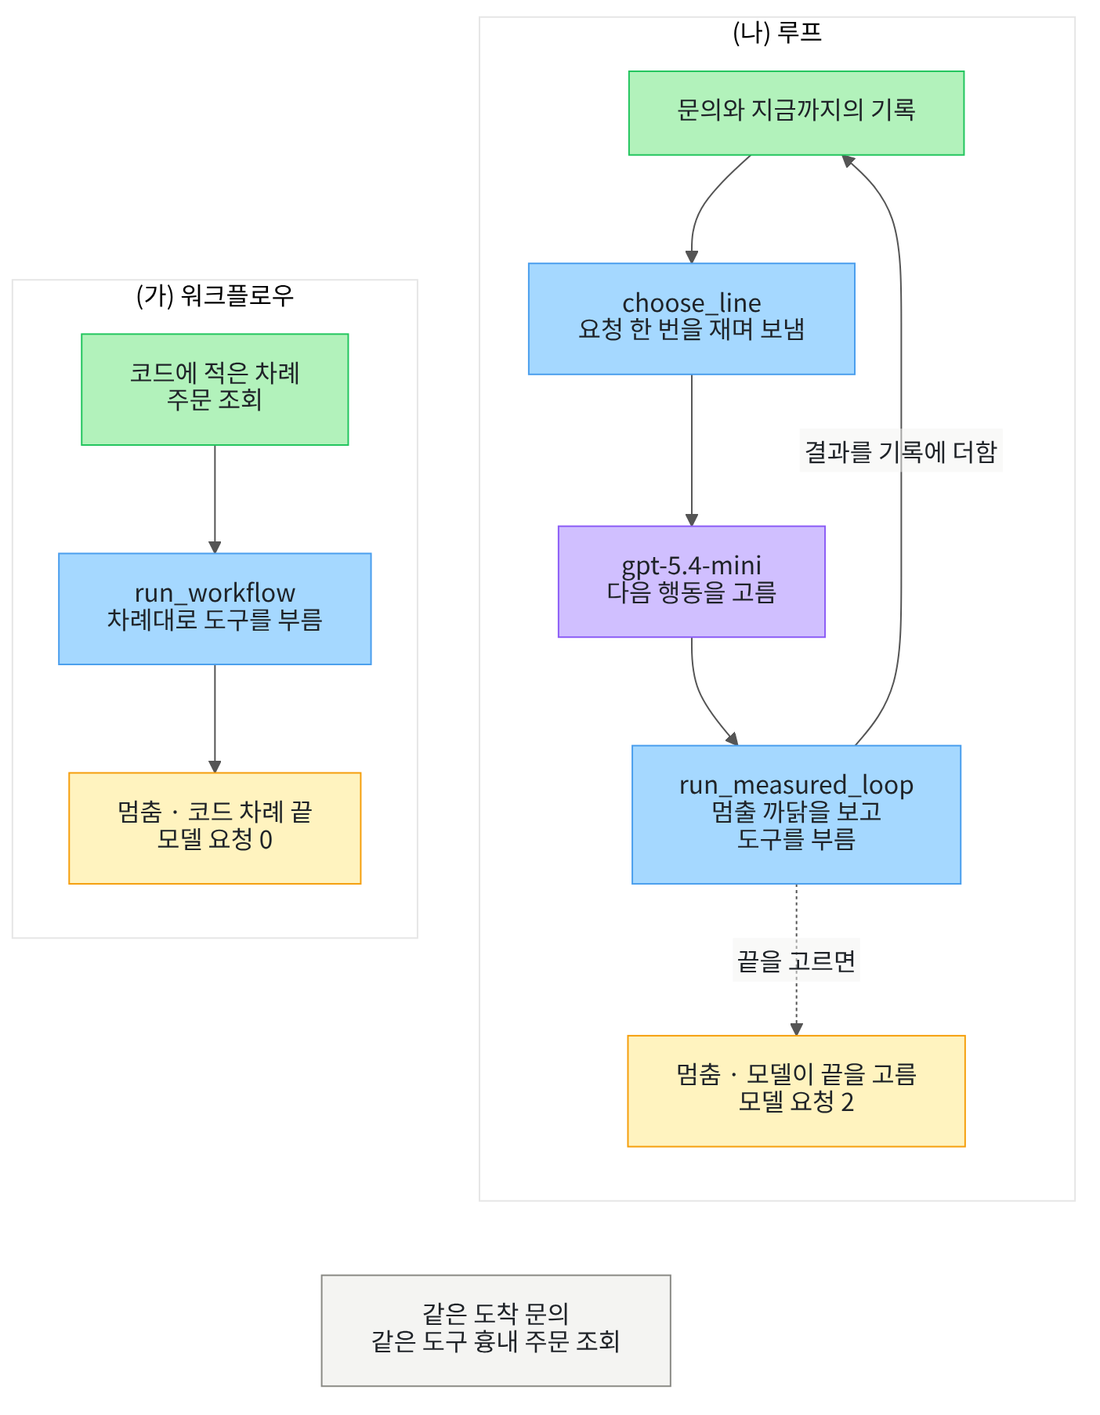

## 1. 준비

이 절은 실제 모델을 부릅니다.
첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.1`이 실습 폴더 잠금과 같은 판입니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다.
앞에서 배운 함수는 `agent_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

이 절에서 처음 가져오는 함수는 03절 함수 여섯과 Ch 6 06절 함수 `estimate_cost`입니다.
03절 함수는 03절 노트북과 같은 본문으로 도구 파일에 옮겼습니다.
함수 `estimate_cost`도 Ch 6 06절 노트북과 같은 본문입니다.

In [2]:
# 시간을 잴 이름·모델 글을 읽을 이름·모델 준비 함수와, 앞에서 배운 함수를 불러옵니다
import json
import time

from agent_tools import classify, count_steps, estimate_cost, tool_names
from agent_tools import build_request, print_results, run_tool, stop_line, stop_reason, turn_lines
from langchain.chat_models import init_chat_model

print("불러온 이름:", "json", "time", "init_chat_model")

불러온 이름: json time init_chat_model


**결과 읽기** — 출력 줄 `불러온 이름: json time init_chat_model`로 이름 셋을 불러왔습니다.
이름 `time`은 Ch 6 06절처럼 걸린 시간을 잴 때 씁니다.
도구 파일에서 가져온 함수 열 개는 출력하지 않습니다.
그 이름은 셀의 두 줄 `from agent_tools import …`에 적혀 있습니다.

## 2. 키와 모델 준비

이 절도 03절과 같은 모델 `gpt-5.4-mini`를 같은 설정으로 부릅니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도 모델이 고르는 행동과 쓰는 글이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-23에 이 모델로 실행한 결과입니다.

## 3. 03절의 도구와 머리글

이 절은 03절에서 만든 도구 흉내 셋과 머리글을 그대로 씁니다.
도구 흉내 함수 `run_tool`은 도구 파일에서 가져왔습니다.
다음 셀은 도구 이름 셋과 사람 확인이 필요한 도구, 바퀴마다 보낼 머리글을 03절과 같게 적습니다.

In [5]:
# 03절과 같은 도구 이름 셋·사람 확인 도구·바퀴마다 보낼 머리글을 다시 적습니다
tool_list = ["주문 조회", "환불 규정 확인", "환불 요청 등록"]
confirm_tools = ["환불 요청 등록"]
request_head = "손님 문의를 처리하고 있습니다. 다음에 부를 도구 하나를 고르세요.\n"
request_head = request_head + "쓸 수 있는 도구: " + ", ".join(tool_list) + "\n"
request_head = request_head + "더 부를 도구가 없으면 끝을 고르세요.\n"
request_head = request_head + 'JSON만 출력하세요: {"다음": "도구 이름 또는 끝", "까닭": "한 문장"}'
print("사람 확인이 필요한 도구:", confirm_tools)
print("머리글:")
print(request_head)

사람 확인이 필요한 도구: ['환불 요청 등록']
머리글:
손님 문의를 처리하고 있습니다. 다음에 부를 도구 하나를 고르세요.
쓸 수 있는 도구: 주문 조회, 환불 규정 확인, 환불 요청 등록
더 부를 도구가 없으면 끝을 고르세요.
JSON만 출력하세요: {"다음": "도구 이름 또는 끝", "까닭": "한 문장"}


**결과 읽기** — 출력 줄 `사람 확인이 필요한 도구: ['환불 요청 등록']`은 03절과 같은 목록입니다.
라벨 줄 `머리글:` 아래 네 줄은 03절 노트북 4절에서 출력한 머리글과 같은 글입니다.

두 흐름에 줄 문의는 03절의 도착 문의입니다.
(가) 워크플로우는 문의 글을 읽지 않고, 코드에 적어 둔 도구 차례만 따릅니다.
도착했는지 알려면 주문 조회 하나면 되니, 코드 차례도 주문 조회 하나로 적습니다.

In [6]:
# 두 흐름에 줄 도착 문의와, (가) 워크플로우가 따를 코드 차례를 적습니다
delivery_question = "주문 A-1024가 도착했는지 알려 주세요."
delivery_order = ["주문 조회"]
print("도착 문의:", delivery_question)
print("(가)의 코드 차례:", delivery_order)

도착 문의: 주문 A-1024가 도착했는지 알려 주세요.
(가)의 코드 차례: ['주문 조회']


**결과 읽기** — 출력 줄 `도착 문의: 주문 A-1024가 도착했는지 알려 주세요.`가 두 흐름에 줄 문의입니다.
출력 줄 `(가)의 코드 차례: ['주문 조회']`는 사람이 이 문의를 보고 정해 적은 차례입니다.
문의와 코드 차례는 흐름을 보여 주려고 이 절에서 정한 값입니다.

## 4. (가) 워크플로우 · 코드가 정한 차례

01절에서 워크플로우는 모델과 도구가 코드에 미리 적어 둔 차례대로 실행되는 구조라고 했습니다.
다음 셀은 목록에 적은 차례대로 도구 흉내를 부르는 함수입니다.
도구 줄의 칸 「고른 쪽」은 `코드`입니다. 그 도구를 부르기로 정한 쪽이 코드이기 때문입니다.

사람 확인이 필요한 도구에 닿으면 03절 함수 `stop_line`으로 멈춤 줄을 더하고 멈춥니다.
적어 둔 차례를 끝까지 따르면 까닭이 `코드 차례 끝`인 멈춤 줄을 더합니다.

In [7]:
# (가) 워크플로우: 코드에 적어 둔 차례대로 도구를 부르고, 사람 확인이 필요한 도구 앞에서 멈춥니다
def run_workflow(order, confirm_tools):
    steps = []
    for name in order:
        if name in confirm_tools:
            return steps + [stop_line("사람 확인")]
        tool_line = {"단계": name, "한 쪽": "도구", "고른 쪽": "코드", "결과": run_tool(name)}
        steps = steps + [tool_line]
    return steps + [stop_line("코드 차례 끝")]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `run_workflow`는 모델을 부르지 않고, 문의 글도 인자로 받지 않습니다.
어느 도구를 부를지는 인자 `order`에 적은 차례가 모두 정합니다.

다음 셀은 (가)를 실행하고 처음부터 끝까지 걸린 초를 잽니다.
Ch 6 06절처럼 실행 앞뒤에서 `time.perf_counter()`를 읽어 빼면 그 사이에 걸린 초입니다.
Ch 15 05절처럼 `round(…, 3)`으로 소수 셋째 자리까지 남깁니다.

In [8]:
# (가)를 도착 문의로 실행하고, 처음부터 끝까지 걸린 초를 잽니다(모델 요청 없음)
start_time = time.perf_counter()
flow_steps = run_workflow(delivery_order, confirm_tools)
flow_seconds = round(time.perf_counter() - start_time, 3)
print_results(flow_steps)
print("전체 걸린 초:", flow_seconds)

번호 | 단계 | 한 쪽 | 고른 쪽 | 결과
0 | 주문 조회 | 도구 | 코드 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일
1 | 멈춤 | 코드 | 코드 | 코드 차례 끝
전체 걸린 초: 0.0


**결과 읽기** — 라벨 줄 `번호 | 단계 | 한 쪽 | 고른 쪽 | 결과` 아래 두 줄이 (가)의 기록입니다.
출력 줄 `0 | 주문 조회 | 도구 | 코드 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일`에서 도구를 고른 쪽은 코드입니다.
출력 줄 `1 | 멈춤 | 코드 | 코드 | 코드 차례 끝`에서 적어 둔 차례가 끝나 멈췄습니다.
출력 줄 `전체 걸린 초: 0.0`은 소수 셋째 자리에서 0이 되었다는 뜻입니다.

(가)는 노트북 안에서 도구 흉내만 불렀습니다.
모델 요청을 기다리지 않아, 걸린 초가 1000분의 1초의 절반에도 닿지 않았습니다.

## 5. 모델 요청 한 번 재기

(나)는 바퀴마다 모델에게 다음 행동을 묻습니다.
그래서 먼저 모델 요청 한 번에 무엇이 드는지 잽니다.
Ch 6 06절에서는 응답 객체의 `usage_metadata`로 입력 토큰 수와 출력 토큰 수를 읽었습니다.
입력 토큰은 모델이 읽은 글의 토큰 수이고, 출력 토큰은 모델이 쓴 글의 토큰 수입니다.
다음 셀은 도착 문의 첫 바퀴의 요청 글을 보내고 걸린 초와 두 토큰 수를 읽습니다.

In [9]:
# 도착 문의 첫 바퀴의 요청 글을 보내고, 앞뒤 시각과 응답의 사용량을 읽습니다(모델 요청 1번)
first_request = build_request(request_head, delivery_question, [])
start_time = time.perf_counter()
first_reply = model.invoke(first_request)
first_seconds = round(time.perf_counter() - start_time, 3)
first_usage = first_reply.usage_metadata
print("받은 글:", first_reply.text)
print("입력 토큰:", first_usage["input_tokens"])
print("출력 토큰:", first_usage["output_tokens"])
print("걸린 초:", first_seconds)

받은 글: {"다음":"주문 조회","까닭":"주문 A-1024의 배송/도착 여부를 확인하려면 주문 조회가 필요합니다."}
입력 토큰: 114
출력 토큰: 38
걸린 초: 0.953


**결과 읽기** — 출력 줄 `받은 글:` 뒤가 모델이 보낸 JSON 글이고, 칸 「다음」의 값은 `주문 조회`입니다.
출력 줄 `입력 토큰: 114`는 모델이 이 요청 글을 읽은 토큰 수입니다.
출력 줄 `출력 토큰:`과 `걸린 초:` 뒤는 모델이 쓴 글의 토큰 수와 이 요청 한 번에 걸린 초입니다.

이번 실행에서는 출력 토큰이 38개, 걸린 초가 0.953초였습니다.
칸 「까닭」 문장과 출력 토큰, 걸린 초는 실행마다 달라질 수 있습니다.
노트북 밖에서 같은 요청을 다섯 번 보냈을 때 입력 토큰은 다섯 번 모두 114였습니다.
출력 토큰은 38개와 40개 사이에서 달랐고, 걸린 초도 매번 달랐습니다.

요청마다 이 셋을 적으려면 같은 코드를 매번 되풀이해야 합니다.
다음 셀은 요청 글 하나를 보내고, 받은 글과 잰 값 셋을 딕셔너리 하나로 내놓는 함수입니다.
Ch 6 06절 함수 `timed_invoke`는 응답과 걸린 초 두 값을 함께 내놓았습니다.
이 함수는 쓸 값만 칸 이름을 붙여 딕셔너리 하나에 담습니다.

In [10]:
# 요청 글 하나를 모델에 보내고 받은 글·걸린 초·입력 토큰·출력 토큰을 딕셔너리로 내놓습니다(모델 요청 1번)
def send_and_measure(chat_model, request_text):
    start_time = time.perf_counter()
    reply = chat_model.invoke(request_text)
    seconds = round(time.perf_counter() - start_time, 3)
    usage = reply.usage_metadata
    measure = {"받은 글": reply.text, "걸린 초": seconds}
    measure["입력 토큰"] = usage["input_tokens"]
    measure["출력 토큰"] = usage["output_tokens"]
    return measure

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `send_and_measure`는 부를 때마다 모델 요청을 한 번 보냅니다.
칸은 「받은 글」·「걸린 초」·「입력 토큰」·「출력 토큰」 넷입니다.
두 시각을 함수 안에서 요청 바로 앞뒤에 읽어, 걸린 초에는 요청 한 번만 들어갑니다.

03절 함수 `ask_next`는 모델이 고른 이름 하나만 내놓았습니다.
그래서 바퀴마다 잰 값을 기록에 남길 자리가 없었습니다.
다음 셀은 함수 `ask_next`와 같은 일을 하되, 기록 한 줄을 내놓는 함수입니다.
03절 칸 넷 「단계」·「한 쪽」·「고른 쪽」·「결과」는 그대로 두고, 잰 값 칸 셋만 더합니다.

In [11]:
# 03절 ask_next처럼 다음 행동을 묻고, 잰 값 셋을 더한 「다음 단계 고르기」 줄을 내놓습니다(모델 요청 1번)
def choose_line(chat_model, head, question, steps):
    request_text = build_request(head, question, steps)
    measure = send_and_measure(chat_model, request_text)
    choice = json.loads(measure["받은 글"])
    line = {"단계": "다음 단계 고르기", "한 쪽": "모델", "고른 쪽": "코드", "결과": choice["다음"]}
    line["입력 토큰"] = measure["입력 토큰"]
    line["출력 토큰"] = measure["출력 토큰"]
    line["걸린 초"] = measure["걸린 초"]
    return line

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `choose_line`은 03절 함수 `build_request`로 요청 글을 만들고, 받은 JSON 글을 `json.loads`로 읽습니다.
칸 「결과」에는 모델이 고른 이름이 들어갑니다.
칸 「입력 토큰」·「출력 토큰」·「걸린 초」에는 잰 값이 들어갑니다.
받은 글이 JSON 모양이 아니면 `json.loads`에서 멈춥니다.

## 6. (나) 루프 · 모델이 고르는 차례

다음 셀은 03절 함수 `run_loop`와 같은 차례로 도는 루프 함수입니다.
다른 점은 고른 줄을 함수 `choose_line`이 만든다는 것 하나입니다.
03절 함수 `turn_lines`는 고른 줄과 그다음 줄, 두 줄을 내놓습니다.
그 가운데 첫 줄은 잰 값이 없는 고른 줄이라, `[1:]`로 빼고 둘째 줄만 이어 붙입니다.
멈출 까닭을 찾는 함수와 바퀴 한도는 03절과 같습니다.

In [12]:
# (나) 루프: 03절 run_loop와 같은 차례로 돌되, 고른 줄은 잰 값이 든 줄로 씁니다
def run_measured_loop(chat_model, head, question, confirm_tools, turn_limit):
    steps = []
    for turn in range(turn_limit):
        choose = choose_line(chat_model, head, question, steps)
        reason = stop_reason(choose["결과"], steps, confirm_tools)
        steps = steps + [choose] + turn_lines(choose["결과"], reason)[1:]
        if reason != "":
            return steps
    return steps + [stop_line("바퀴 한도")]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `run_measured_loop`가 만드는 기록은 03절 `run_loop`의 기록과 줄 차례가 같습니다.
고른 줄에만 잰 값 칸 셋이 더 있습니다.

다음 셀은 같은 도착 문의로 (나)를 실행합니다.
바퀴 한도는 03절과 같은 4이고, 바퀴마다 모델 요청이 한 번 나갑니다.
(가)처럼 실행 앞뒤 시각으로 전체 걸린 초도 잽니다.

In [13]:
# (나) 같은 도착 문의를 모델이 고르는 루프로 실행하고 전체 걸린 초를 잽니다(모델 요청 네 번까지)
turn_limit = 4
start_time = time.perf_counter()
loop_steps = run_measured_loop(model, request_head, delivery_question, confirm_tools, turn_limit)
loop_seconds = round(time.perf_counter() - start_time, 3)
print_results(loop_steps)
print("전체 걸린 초:", loop_seconds)

번호 | 단계 | 한 쪽 | 고른 쪽 | 결과
0 | 다음 단계 고르기 | 모델 | 코드 | 주문 조회
1 | 주문 조회 | 도구 | 모델 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일
2 | 다음 단계 고르기 | 모델 | 코드 | 끝
3 | 멈춤 | 코드 | 모델 | 모델이 끝을 고름
전체 걸린 초: 1.854


**결과 읽기** — 라벨 줄 아래 네 줄이 (나)의 기록입니다.
출력 줄 `0 | 다음 단계 고르기 | 모델 | 코드 | 주문 조회`에서 모델이 주문 조회를 골랐습니다.
출력 줄 `3 | 멈춤 | 코드 | 모델 | 모델이 끝을 고름`에서 둘째 바퀴에 끝을 골라 멈췄습니다.
03절 노트북 7절의 도착 문의 기록과 같은 네 줄입니다.

이번 실행에서는 전체 걸린 초가 1.854초였습니다.
걸린 초는 실행마다 달라질 수 있습니다.

기록의 칸 「단계」를 번호 차례대로 읽은 것을 단계 차례(궤적, trajectory)라고 부릅니다.
눈 위의 발자국을 찍힌 차례대로 따라가며 읽는 것과 같습니다.
(나)의 단계 차례는 다음 단계 고르기, 주문 조회, 다음 단계 고르기, 멈춤입니다.
4절 (가)의 단계 차례는 주문 조회, 멈춤이었습니다.

다음 셀은 기록에서 고른 줄만 골라 바퀴마다 잰 값을 출력하는 함수입니다.
칸 「한 쪽」이 모델인 줄이 고른 줄이고, 02절 약속대로 그 줄 하나가 모델 요청 한 번입니다.

In [14]:
# 기록에서 모델이 한 줄만 골라 바퀴마다 고른 이름과 잰 값 셋을 출력합니다
def print_measures(steps):
    print("바퀴 | 고른 이름 | 입력 토큰 | 출력 토큰 | 걸린 초")
    turn = 0
    for step in steps:
        if step["한 쪽"] == "모델":
            turn = turn + 1
            print(turn, "|", step["결과"], "|", step["입력 토큰"], "|", step["출력 토큰"], "|", step["걸린 초"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_measures`는 라벨 줄을 먼저 출력합니다.
그다음 고른 줄마다 바퀴 번호를 1부터 붙여 한 줄씩 출력합니다.

다음 셀은 (나)의 바퀴마다 잰 값을 보고, 01절 함수 `count_steps`로 바퀴 수를 셉니다.
새 요청은 보내지 않습니다.

In [15]:
# (나) 기록에서 바퀴마다 잰 값을 보고 바퀴 수를 셉니다(요청 없음)
print_measures(loop_steps)
print("바퀴 수:", count_steps(loop_steps, "한 쪽", "모델"))

바퀴 | 고른 이름 | 입력 토큰 | 출력 토큰 | 걸린 초
1 | 주문 조회 | 114 | 39 | 0.992
2 | 끝 | 136 | 43 | 0.861
바퀴 수: 2


**결과 읽기** — 라벨 줄 `바퀴 | 고른 이름 | 입력 토큰 | 출력 토큰 | 걸린 초` 아래 두 줄이 두 바퀴의 잰 값입니다.
첫 바퀴의 입력 토큰은 `114`, 둘째 바퀴의 입력 토큰은 `136`입니다.
출력 줄 `바퀴 수: 2`처럼 모델 요청은 두 번 나갔습니다.

둘째 바퀴 요청 글에는 첫 바퀴에 부른 주문 조회의 결과 한 줄이 더 붙습니다.
그래서 입력 토큰이 22개 늘었습니다.
루프는 바퀴마다 머리글과 문의, 지금까지의 결과를 모두 다시 보냅니다.
바퀴가 늘수록 요청 글이 길어져 요청 한 번의 입력 토큰도 커집니다.

이번 실행에서는 출력 토큰이 39개와 43개, 걸린 초가 0.992초와 0.861초였습니다.
이 두 칸은 실행마다 달라질 수 있습니다.

5절에서 보낸 요청과 (나)의 첫 바퀴 요청은 요청 글이 글자까지 같습니다.
둘 다 도착 문의와 빈 기록으로 03절 함수 `build_request`가 만든 글이기 때문입니다.
다음 셀은 두 요청의 잰 값을 나란히 봅니다.

In [16]:
# 5절에서 보낸 요청과 루프 첫 바퀴 요청은 요청 글이 같습니다: 잰 값을 나란히 봅니다
first_turn = loop_steps[0]
print("잰 값 | 5절 요청 | 첫 바퀴 요청")
print("입력 토큰 |", first_usage["input_tokens"], "|", first_turn["입력 토큰"])
print("출력 토큰 |", first_usage["output_tokens"], "|", first_turn["출력 토큰"])
print("걸린 초 |", first_seconds, "|", first_turn["걸린 초"])
print("입력 토큰이 같은가:", first_usage["input_tokens"] == first_turn["입력 토큰"])

잰 값 | 5절 요청 | 첫 바퀴 요청
입력 토큰 | 114 | 114
출력 토큰 | 38 | 39
걸린 초 | 0.953 | 0.992
입력 토큰이 같은가: True


**결과 읽기** — 라벨 줄 `잰 값 | 5절 요청 | 첫 바퀴 요청` 아래 세 줄을 견줍니다.
출력 줄 `입력 토큰 | 114 | 114`처럼 같은 요청 글은 입력 토큰이 같았습니다.
출력 줄 `입력 토큰이 같은가: True`로 그것을 확인했습니다.

이번 실행에서는 출력 토큰이 38개와 39개, 걸린 초가 0.953초와 0.992초로 둘 다 달랐습니다.
입력 토큰은 보낸 요청 글로 정해집니다.
출력 토큰은 모델이 쓴 글로, 걸린 초는 서버와 네트워크 사정으로 정해져 실행마다 달라질 수 있습니다.

## 7. 두 흐름 나란히 보기

두 흐름을 한 표로 견주려면 기록마다 토큰 수를 더해야 합니다.
다음 셀은 고른 줄의 칸 하나를 모두 더하는 함수입니다.
01절 함수 `count_steps`가 조건에 맞는 줄 수를 셌다면, 이 함수는 칸 값을 더합니다.

In [17]:
# 기록에서 모델이 한 줄의 칸 key 값을 모두 더합니다(토큰 수를 합칠 때 씁니다)
def total_of(steps, key):
    total = 0
    for step in steps:
        if step["한 쪽"] == "모델":
            total = total + step[key]
    return total

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `total_of`는 칸 「한 쪽」이 모델인 줄의 값만 더합니다.
(가)처럼 고른 줄이 없는 기록이면 0을 내놓습니다.

다음 셀은 기록마다 모델 요청 수와 토큰 수 합, 전체 걸린 초, 구조를 한 줄로 출력하는 함수입니다.
기록 하나는 01절 사례처럼 칸 「이름」과 「기록」을 가진 딕셔너리이고, 칸 「걸린 초」를 더했습니다.
구조는 01절 함수 `classify`로 가릅니다.

In [18]:
# 기록마다 모델 요청 수·입력 토큰 합·출력 토큰 합·전체 걸린 초·구조를 한 줄로 출력합니다
def print_costs(runs):
    print("기록 | 모델 요청 | 입력 토큰 | 출력 토큰 | 걸린 초 | 구조")
    for run in runs:
        steps = run["기록"]
        requests = count_steps(steps, "한 쪽", "모델")
        inputs = total_of(steps, "입력 토큰")
        outputs = total_of(steps, "출력 토큰")
        kind = classify(steps)
        print(run["이름"], "|", requests, "|", inputs, "|", outputs, "|", run["걸린 초"], "|", kind)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_costs`는 모델 요청 수를 01절 함수 `count_steps`로 셉니다.
토큰 수 두 칸은 함수 `total_of`로 더합니다.

다음 셀은 도착 문의의 두 기록을 한 표로 견줍니다.
두 흐름이 도구를 부른 차례가 같은지도 02절 함수 `tool_names`로 봅니다.

In [19]:
# (가)와 (나)를 한 표로 견주고, 도구를 부른 차례가 같은지 봅니다
first_runs = [
    {"이름": "(가) 워크플로우", "기록": flow_steps, "걸린 초": flow_seconds},
    {"이름": "(나) 루프", "기록": loop_steps, "걸린 초": loop_seconds},
]
print_costs(first_runs)
print("도구 차례가 같은가:", tool_names(flow_steps) == tool_names(loop_steps))

기록 | 모델 요청 | 입력 토큰 | 출력 토큰 | 걸린 초 | 구조
(가) 워크플로우 | 0 | 0 | 0 | 0.0 | 워크플로우
(나) 루프 | 2 | 250 | 82 | 1.854 | 에이전트 후보
도구 차례가 같은가: True


**결과 읽기** — 라벨 줄 `기록 | 모델 요청 | 입력 토큰 | 출력 토큰 | 걸린 초 | 구조` 아래 두 줄을 견줍니다.
출력 줄 `(가) 워크플로우 | 0 | 0 | 0 | 0.0 | 워크플로우`에서 (가)는 모델 요청이 없습니다.
(나) 줄은 모델 요청 `2`, 입력 토큰 합 `250`이고, 구조는 에이전트 후보입니다.
출력 줄 `도구 차례가 같은가: True`로 두 흐름이 부른 도구는 같았습니다.

이번 실행에서는 (나)의 출력 토큰 합이 82개, 전체 걸린 초가 1.854초였습니다.
이 두 값은 실행마다 달라질 수 있습니다.

두 흐름은 같은 도구를 불러 같은 결과 글을 받았습니다.
다른 것은 다음 단계를 누가 골랐는가 하나입니다.
(나)는 그 선택마다 모델 요청 한 번과 요청 글 길이만큼의 입력 토큰을 더 썼습니다.
끝을 고르는 데에도 요청이 한 번 들었습니다.

이 차이를 이 절에서는 자율성의 대가라고 부릅니다.
장 볼 목록 없이 가게에 가면 진열대마다 멈춰 살 것을 고르느라 시간이 더 드는 것과 같습니다.
이 셀에서는 표의 (가) 줄과 (나) 줄의 차이가 자율성의 대가입니다.

## 8. 요금표로 예상 비용 세기

토큰 수에 요금을 곱하면 대가를 돈으로 볼 수 있습니다.
Ch 6 06절에서는 요금표와 함수 `estimate_cost`로 요청 한 번의 예상 비용을 셌습니다.
예상 비용은 요금표로 어림한 값이고 청구 금액이 아닙니다.
Ch 16 04절은 요청 하나에 예상 비용 0.002달러를 정해 두고 예약했습니다.
이 절의 예상 비용은 그렇게 정해 둔 값이 아니라, Ch 6 06절처럼 받은 토큰 수로 센 값입니다.

다음 셀은 (나)의 토큰 수 합으로 사용량 딕셔너리를 만들어 함수에 넘깁니다.
이 딕셔너리에는 캐시 입력 칸이 없어, 함수가 캐시 입력을 0으로 셉니다.
노트북 밖에서 이 절의 요청을 보냈을 때 캐시 입력은 모두 0이었습니다.

In [20]:
# Ch 6 06절 요금표(100만 토큰당 달러)로 (나) 루프의 예상 비용을 셉니다(요청 없음)
pricing_date = "2026-09-17"
mini_prices = {"ordinary_input": 0.75, "cached_input": 0.075, "output": 4.50}
loop_usage = {"input_tokens": total_of(loop_steps, "입력 토큰")}
loop_usage["output_tokens"] = total_of(loop_steps, "출력 토큰")
loop_cost = estimate_cost(
    loop_usage, mini_prices["ordinary_input"], mini_prices["cached_input"], mini_prices["output"]
)
print("요금 확인 날짜:", pricing_date)
print("(나) 루프 예상 비용(달러):", round(loop_cost, 6))

요금 확인 날짜: 2026-09-17
(나) 루프 예상 비용(달러): 0.000557


**결과 읽기** — 출력 줄 `요금 확인 날짜: 2026-09-17`은 Ch 6 06절 요금표를 확인한 날짜입니다.
출력 줄 `(나) 루프 예상 비용(달러):` 뒤가 (나)의 예상 비용입니다.
(가)는 모델 요청이 없어 예상 비용이 0입니다.

이번 실행에서는 (나)의 예상 비용이 0.000557달러였습니다.
출력 토큰 요금은 100만 토큰당 4.50달러로 입력 토큰 요금의 여섯 배입니다.
그래서 출력 토큰 수가 조금만 달라져도 예상 비용이 달라집니다.

## 9. 값 바꿔 보기 · 환불 문의

바꿀 값은 문의 하나입니다. 도착 문의를 03절 환불 문의로 바꿉니다.
(가)는 문의 글을 읽지 않으므로, 이 문의에 맞는 코드 차례를 사람이 새로 적어야 합니다.
02절 코드가 고른 환불 기록과 같은 도구 차례로 적습니다.
(나)는 함수와 머리글을 그대로 두고 문의만 바꿉니다.

실행 전에 예상해 봅니다.
(가)는 이번에도 모델 요청이 없고, 환불 요청 등록 앞에서 사람 확인으로 멈출 것입니다.
(나)는 03절 8절처럼 세 바퀴를 돌아 사람 확인에서 멈추고, 모델 요청은 세 번일 것입니다.
바퀴마다 앞 도구의 결과 한 줄이 붙으니 입력 토큰도 바퀴마다 늘 것입니다.

In [21]:
# 바꿀 값: 문의를 03절 환불 문의로 바꿉니다. (가)는 이 문의에 맞는 코드 차례를 새로 적습니다
refund_question = "주문 A-1024를 환불해 주세요."
refund_order = ["주문 조회", "환불 규정 확인", "환불 요청 등록"]
start_time = time.perf_counter()
flow_refund = run_workflow(refund_order, confirm_tools)
flow_refund_seconds = round(time.perf_counter() - start_time, 3)
print_results(flow_refund)

번호 | 단계 | 한 쪽 | 고른 쪽 | 결과
0 | 주문 조회 | 도구 | 코드 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일
1 | 환불 규정 확인 | 도구 | 코드 | 받은 지 7일 안의 상품은 환불할 수 있음
2 | 멈춤 | 코드 | 코드 | 사람 확인


**결과 읽기** — 라벨 줄 아래 세 줄이 (가)의 환불 기록입니다.
출력 줄 `2 | 멈춤 | 코드 | 코드 | 사람 확인`에서 코드가 등록 도구를 부르기 전에 멈췄습니다.
(가)에 대한 예상과 맞았습니다.

다음 셀은 (나)를 환불 문의로 실행합니다.

In [22]:
# (나)는 함수와 머리글을 그대로 두고 문의만 바꿔 실행합니다(모델 요청 네 번까지)
start_time = time.perf_counter()
loop_refund = run_measured_loop(model, request_head, refund_question, confirm_tools, turn_limit)
loop_refund_seconds = round(time.perf_counter() - start_time, 3)
print_results(loop_refund)

번호 | 단계 | 한 쪽 | 고른 쪽 | 결과
0 | 다음 단계 고르기 | 모델 | 코드 | 주문 조회
1 | 주문 조회 | 도구 | 모델 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일
2 | 다음 단계 고르기 | 모델 | 코드 | 환불 규정 확인
3 | 환불 규정 확인 | 도구 | 모델 | 받은 지 7일 안의 상품은 환불할 수 있음
4 | 다음 단계 고르기 | 모델 | 코드 | 환불 요청 등록
5 | 멈춤 | 코드 | 코드 | 사람 확인


**결과 읽기** — 라벨 줄 `번호 | 단계 | 한 쪽 | 고른 쪽 | 결과` 아래가 (나)의 환불 기록입니다.
마지막 줄은 칸 「결과」가 `사람 확인`이고 칸 「고른 쪽」이 `코드`인 멈춤 줄입니다.
모델이 무엇을 골랐든 환불 요청 등록은 불리지 않았습니다.

이번 실행에서는 03절 8절처럼 주문 조회, 환불 규정 확인, 환불 요청 등록 차례로 골랐습니다.
(나)에 대한 예상과 맞았습니다.
노트북 밖에서 같은 루프를 다섯 번 실행했을 때는 한 번 첫 바퀴에 환불 요청 등록을 골랐습니다.
그렇게 고르면 기록은 고른 줄과 멈춤 줄 두 줄로 끝나고, 모델 요청은 1번이 됩니다.

다음 셀은 환불 문의의 두 기록을 한 표로 견주고, (나)의 바퀴마다 잰 값을 봅니다.

In [23]:
# 환불 문의의 두 기록을 한 표로 견주고, (나)의 바퀴마다 잰 값을 봅니다
refund_runs = [
    {"이름": "(가) 워크플로우", "기록": flow_refund, "걸린 초": flow_refund_seconds},
    {"이름": "(나) 루프", "기록": loop_refund, "걸린 초": loop_refund_seconds},
]
print_costs(refund_runs)
print_measures(loop_refund)

기록 | 모델 요청 | 입력 토큰 | 출력 토큰 | 걸린 초 | 구조
(가) 워크플로우 | 0 | 0 | 0 | 0.0 | 워크플로우
(나) 루프 | 3 | 399 | 133 | 2.894 | 에이전트 후보
바퀴 | 고른 이름 | 입력 토큰 | 출력 토큰 | 걸린 초
1 | 주문 조회 | 111 | 37 | 0.954
2 | 환불 규정 확인 | 133 | 43 | 1.039
3 | 환불 요청 등록 | 155 | 53 | 0.9


**결과 읽기** — 라벨 줄 `기록 | 모델 요청 | 입력 토큰 | 출력 토큰 | 걸린 초 | 구조` 아래 첫 줄이 (가)입니다.
출력 줄 `(가) 워크플로우 | 0 | 0 | 0 | 0.0 | 워크플로우`는 도착 문의 때와 같습니다.
라벨 줄 `바퀴 | 고른 이름 | 입력 토큰 | 출력 토큰 | 걸린 초` 아래 첫 줄에서 첫 바퀴의 입력 토큰은 `111`입니다.

이번 실행에서는 (나) 줄이 모델 요청 3번, 입력 토큰 합 399, 출력 토큰 합 133, 전체 걸린 초 2.894초였습니다.
바퀴별 입력 토큰은 111, 133, 155로 바퀴마다 22개씩 늘었습니다.
첫 바퀴에 환불 요청 등록을 골랐다면 이 줄은 모델 요청 1번, 입력 토큰 합 111이 됩니다.

문의가 바뀌자 (가)는 코드 차례를 새로 적어야 했습니다.
(나)는 같은 함수와 머리글로 두 문의를 모두 처리했습니다.
문의마다 차례를 미리 적지 않아도 되는 것이 모델에게 고르게 두어 얻는 것입니다.
그 대신 (나)가 몇 바퀴를 돌지는 모델이 고른 뒤에야 정해집니다.
노트북 밖에서 환불 문의로 다섯 번 실행했을 때, 한 번은 첫 바퀴에 환불 요청 등록을 골랐습니다.

## 정리

1. 같은 도착 문의에서 (가) 워크플로우는 모델 요청이 없었고, (나) 루프는 두 번이었습니다.
2. 같은 요청 글이면 입력 토큰이 같았고, 바퀴마다 요청 글이 길어져 입력 토큰이 늘었습니다.
3. 걸린 초와 출력 토큰은 실행마다 달랐고, (나)의 요청 수는 모델이 고른 뒤에야 정해졌습니다.

05절에서는 공개된 실행 기록 자료를 읽고 자율성을 진단합니다.